# Magic Pen (Air Gesture Drawing Model Training)

In this phase, we focus on training a robust machine learning model capable of recognizing specific hand gestures in real-time. By leveraging spatial data, the system translates physical hand movements into digital commands for an **Air Gesture Drawing** interface.

---

### System Overview
The pipeline follows a structured approach to transform raw video frames into actionable gesture classifications:

1.  **Hand Landmark Extraction:** Using **MediaPipe Hands**, we detect and track 21 3D hand landmarks.
2.  **Feature Engineering:** The $(x, y, z)$ coordinates of these landmarks are normalized to ensure the model remains scale and rotation invariant.
3.  **Gesture Classification:** A classifier categorizes the landmark patterns into four primary states:

| Gesture | Action | Description |
| :--- | :--- | :--- |
| **Draw** | ✍️ | Index finger extended; allows the user to write on the virtual canvas. |
| **Erase** | 🧼 | Multi-finger or fist gesture; clears specific areas or the entire screen. |
| **Scroll** | ↕️ | Specific hand movement to navigate through menus or pages. |
| **Cursor** | 🖱️ | Hand open; moves the pointer without active drawing. |

---

### 🎯 Objective
The goal of this notebook is to:
* **Preprocess** the collected landmark dataset.
* **Train** a classification model.
* **Evaluate** the model using a confusion matrix to ensure high precision across all gestures.
* **Export** the trained weights for integration into the real-time application.

#### **Data Exploration**

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [5]:
pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpy

In [2]:
df = pd.read_excel("final_gesture_data.xlsx")

df.head()

,label,Lx0,Ly0,Lz0,Lx1,Ly1,Lz1,Lx2,Ly2,Lz2,...,Rz17,Rx18,Ry18,Rz18,Rx19,Ry19,Rz19,Rx20,Ry20,Rz20
0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.024006,0.640282,0.638152,-0.043547,0.636939,0.677689,-0.036370,0.644005,0.714818,-0.025161
1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.017363,0.644825,0.643655,-0.034172,0.642093,0.680825,-0.028700,0.646941,0.717298,-0.019838
2,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.002029,0.611983,0.575341,-0.008682,0.607034,0.606629,-0.000598,0.612013,0.638193,0.008795
3,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.007133,0.551270,0.492378,0.004686,0.545436,0.519785,0.013260,0.552976,0.545225,0.022690
4,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.007748,0.548172,0.460406,-0.020481,0.540783,0.504239,-0.011554,0.552928,0.537528,0.000851


In [3]:
df.tail()

,label,Lx0,Ly0,Lz0,Lx1,Ly1,Lz1,Lx2,Ly2,Lz2,...,Rz17,Rx18,Ry18,Rz18,Rx19,Ry19,Rz19,Rx20,Ry20,Rz20
5595,6,0.326372,0.467872,2.483249e-07,0.353353,0.450347,-0.011032,0.376471,0.421302,-0.014794,...,-0.018405,0.717264,0.343560,-0.024583,0.719864,0.327258,-0.026216,0.721520,0.312171,-0.027130
5596,6,0.326378,0.468220,2.482392e-07,0.353364,0.450612,-0.010961,0.376424,0.421358,-0.014708,...,-0.018152,0.717169,0.342643,-0.023989,0.719700,0.326572,-0.025382,0.721261,0.311776,-0.026145
5597,6,0.325876,0.467821,2.535308e-07,0.352054,0.450452,-0.011100,0.374720,0.421617,-0.015101,...,-0.018147,0.717594,0.343536,-0.024757,0.721162,0.326918,-0.026508,0.723595,0.311645,-0.027369
5598,6,0.325815,0.468099,2.484789e-07,0.351844,0.450756,-0.011103,0.374599,0.421917,-0.015132,...,-0.018004,0.717567,0.344380,-0.024600,0.721047,0.327536,-0.026406,0.723447,0.312056,-0.027317
5599,6,0.325869,0.468264,2.490479e-07,0.351847,0.450758,-0.011005,0.374577,0.421902,-0.015002,...,-0.017570,0.717617,0.344369,-0.024036,0.721027,0.327566,-0.025820,0.723433,0.312034,-0.026742


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (5600, 127)


In [5]:
print("Data Duplication:", df.duplicated().sum())

Data Duplication: 0


In [6]:
print("\nClass Distribution:\n", df['label'].value_counts())
print("\nMissing Values:\n", df.isnull().sum())


Class Distribution:
 label
0    800
1    800
2    800
3    800
4    800
5    800
6    800
Name: count, dtype: int64

Missing Values:
 label    0
Lx0      0
Ly0      0
Lz0      0
Lx1      0
        ..
Ry19     0
Rz19     0
Rx20     0
Ry20     0
Rz20     0
Length: 127, dtype: int64


#### **Feature Extraction**

In [3]:
X = df.drop("label", axis=1)
y = df["label"]

#### **Normalization**

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#### **Data Splitting**

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)


#### **Model Training**

In [10]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

In [11]:
rf = RandomForestClassifier(random_state=42)

grid = GridSearchCV(rf, param_grid, cv=3, n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_

In [12]:
print("\nBest Parameters:", grid.best_params_)


Best Parameters: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}


#### **Model Evaluation**

In [13]:
y_pred = best_model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9973214285714286
Train Accuracy: 1.0
Test Accuracy: 0.9973214285714286

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.98      0.99       176
           1       1.00      1.00      1.00       153
           2       0.99      1.00      1.00       149
           3       1.00      1.00      1.00       143
           4       0.99      1.00      0.99       175
           5       1.00      1.00      1.00       165
           6       1.00      1.00      1.00       159

    accuracy                           1.00      1120
   macro avg       1.00      1.00      1.00      1120
weighted avg       1.00      1.00      1.00      1120



In [20]:
pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


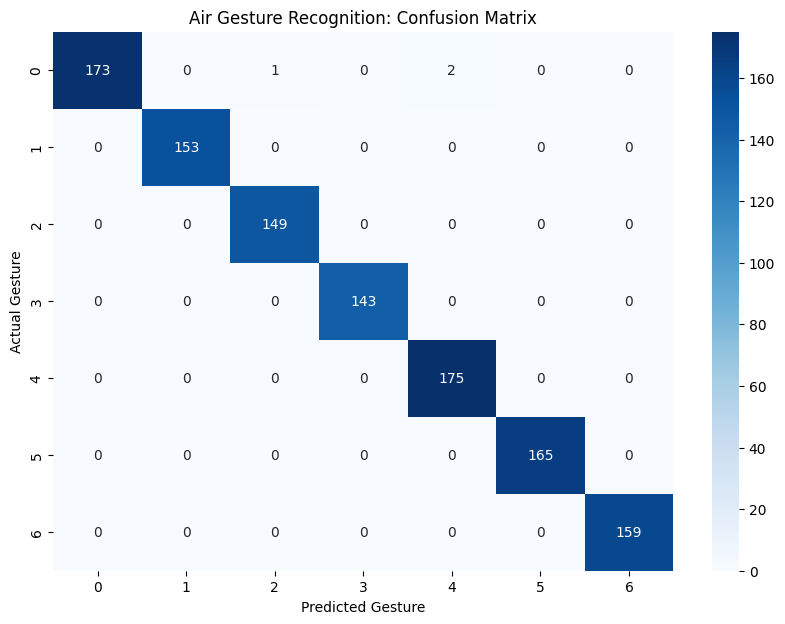

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Air Gesture Recognition: Confusion Matrix')
plt.xlabel('Predicted Gesture')
plt.ylabel('Actual Gesture')
plt.show()

In [ ]:
import joblib

joblib.dump(best_model, "gesture_model1.pkl")
joblib.dump(scaler, "scaler1.pkl")

print("\nModel saved successfully!")


Model saved successfully!


#### **Testing Model**

In [17]:
import cv2
import mediapipe as mp
import numpy as np
import joblib
from collections import deque

model = joblib.load("gesture_model1.pkl")
scaler = joblib.load("scaler1.pkl")

gestures = ["Draw", "Erase", "Cursor", "Scroll", "Color", "Screenshot", "Clear"]

mp_hands = mp.solutions.hands
hands = mp_hands.Hands(
    max_num_hands=2,
    min_detection_confidence=0.7,
    min_tracking_confidence=0.7
)
mp_draw = mp.solutions.drawing_utils

cap = cv2.VideoCapture(0)

gesture_buffer = deque(maxlen=10)

def extract_features_two_hands(results):
    left_hand = np.zeros(63)
    right_hand = np.zeros(63)

    if results.multi_hand_landmarks and results.multi_handedness:
        for hand_landmarks, handedness in zip(results.multi_hand_landmarks, results.multi_handedness):

            hand_features = []
            for lm in hand_landmarks.landmark:
                hand_features.extend([lm.x, lm.y, lm.z])

            if handedness.classification[0].label == "Left":
                left_hand = np.array(hand_features)
            else:
                right_hand = np.array(hand_features)

    features = np.concatenate([left_hand, right_hand])
    return features.reshape(1, -1)

while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame = cv2.flip(frame, 1)

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    result = hands.process(rgb)

    gesture_name = "No Hand"

    if result.multi_hand_landmarks:

        for hand_landmarks in result.multi_hand_landmarks:
            mp_draw.draw_landmarks(frame, hand_landmarks, mp_hands.HAND_CONNECTIONS)

        try:

            features = extract_features_two_hands(result)

            features = scaler.transform(features)

            prediction = model.predict(features)[0]

            if int(prediction) < len(gestures):
                current_gesture = gestures[int(prediction)]
            else:
                current_gesture = "Unknown"

            gesture_buffer.append(current_gesture)
            gesture_name = max(set(gesture_buffer), key=gesture_buffer.count)

        except Exception as e:
            print("Error:", e)

    cv2.putText(frame, f'Gesture: {gesture_name}',
                (10, 50),
                cv2.FONT_HERSHEY_SIMPLEX,
                1,
                (0, 255, 0),
                2)

    cv2.imshow("Air Gesture Recognition", frame)

    if cv2.waitKey(1) & 0xFF == 27:
        break

cap.release()
cv2.destroyAllWindows()

c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\On

### **Training 2**

In [10]:
param_grid = {
    'n_estimators': [100, 200],
    'bootstrap' : [True, False],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'criterion': ['gini', 'entropy']
}

In [11]:
rf = RandomForestClassifier(random_state=42)

grid = GridSearchCV(rf, param_grid, cv=3, n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_

In [12]:
print("\nBest Parameters:", grid.best_params_)


Best Parameters: {'bootstrap': False, 'criterion': 'gini', 'max_depth': 20, 'max_features': 'log2', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}


In [13]:
y_pred = best_model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9973214285714286
Train Accuracy: 1.0
Test Accuracy: 0.9973214285714286

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.98      0.99       176
           1       1.00      1.00      1.00       153
           2       0.99      1.00      1.00       149
           3       1.00      1.00      1.00       143
           4       0.99      1.00      0.99       175
           5       1.00      1.00      1.00       165
           6       1.00      1.00      1.00       159

    accuracy                           1.00      1120
   macro avg       1.00      1.00      1.00      1120
weighted avg       1.00      1.00      1.00      1120



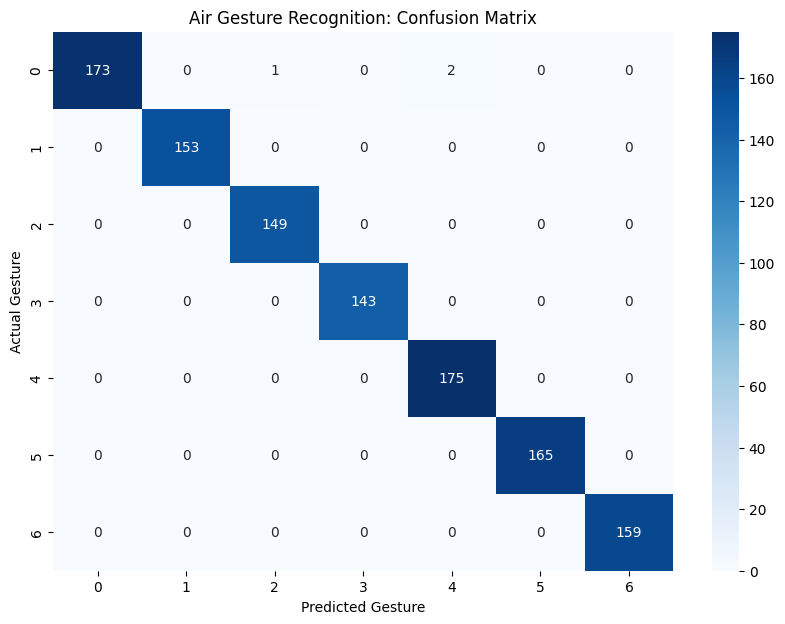

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Air Gesture Recognition: Confusion Matrix')
plt.xlabel('Predicted Gesture')
plt.ylabel('Actual Gesture')
plt.show()

In [15]:
import joblib

joblib.dump(best_model, "gesture_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("\nModel saved successfully!")


Model saved successfully!


In [22]:
import cv2
import mediapipe as mp
import numpy as np
import joblib
from collections import deque

model = joblib.load("gesture_model.pkl")
scaler = joblib.load("scaler.pkl")

gestures = ["Draw", "Erase", "Cursor", "Scroll", "Color", "Screenshot", "Clear"]

mp_hands = mp.solutions.hands
hands = mp_hands.Hands(
    max_num_hands=2,
    min_detection_confidence=0.7,
    min_tracking_confidence=0.7
)
mp_draw = mp.solutions.drawing_utils

cap = cv2.VideoCapture(0)

gesture_buffer = deque(maxlen=10)

def extract_features_two_hands(results):
    left_hand = np.zeros(63)
    right_hand = np.zeros(63)

    if results.multi_hand_landmarks and results.multi_handedness:
        for hand_landmarks, handedness in zip(results.multi_hand_landmarks, results.multi_handedness):

            hand_features = []
            for lm in hand_landmarks.landmark:
                hand_features.extend([lm.x, lm.y, lm.z])

            if handedness.classification[0].label == "Left":
                left_hand = np.array(hand_features)
            else:
                right_hand = np.array(hand_features)

    features = np.concatenate([left_hand, right_hand])
    return features.reshape(1, -1)

while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame = cv2.flip(frame, 1)

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    result = hands.process(rgb)

    gesture_name = "No Hand"

    if result.multi_hand_landmarks:

        for hand_landmarks in result.multi_hand_landmarks:
            mp_draw.draw_landmarks(frame, hand_landmarks, mp_hands.HAND_CONNECTIONS)

        try:

            features = extract_features_two_hands(result)

            features = scaler.transform(features)

            prediction = model.predict(features)[0]

            if int(prediction) < len(gestures):
                current_gesture = gestures[int(prediction)]
            else:
                current_gesture = "Unknown"

            gesture_buffer.append(current_gesture)
            gesture_name = max(set(gesture_buffer), key=gesture_buffer.count)

        except Exception as e:
            print("Error:", e)

    cv2.putText(frame, f'Gesture: {gesture_name}',
                (10, 50),
                cv2.FONT_HERSHEY_SIMPLEX,
                1,
                (0, 255, 0),
                2)

    cv2.imshow("Air Gesture Recognition", frame)

    if cv2.waitKey(1) & 0xFF == 27:
        break

cap.release()
cv2.destroyAllWindows()

c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\On

# **SVM Training**

In [10]:
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf', 'linear'],
    'gamma': ['scale', 0.01, 0.001]
}

In [12]:
from sklearn.svm import SVC
svc = SVC()

grid = GridSearchCV(svc, param_grid, cv=3)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_

In [13]:
print("\nBest Parameters:", grid.best_params_)


Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}


In [14]:
y_pred = best_model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9973214285714286
Train Accuracy: 0.9997767857142857
Test Accuracy: 0.9973214285714286

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       176
           1       1.00      1.00      1.00       153
           2       1.00      0.99      1.00       149
           3       1.00      0.99      1.00       143
           4       0.99      1.00      0.99       175
           5       1.00      1.00      1.00       165
           6       1.00      1.00      1.00       159

    accuracy                           1.00      1120
   macro avg       1.00      1.00      1.00      1120
weighted avg       1.00      1.00      1.00      1120



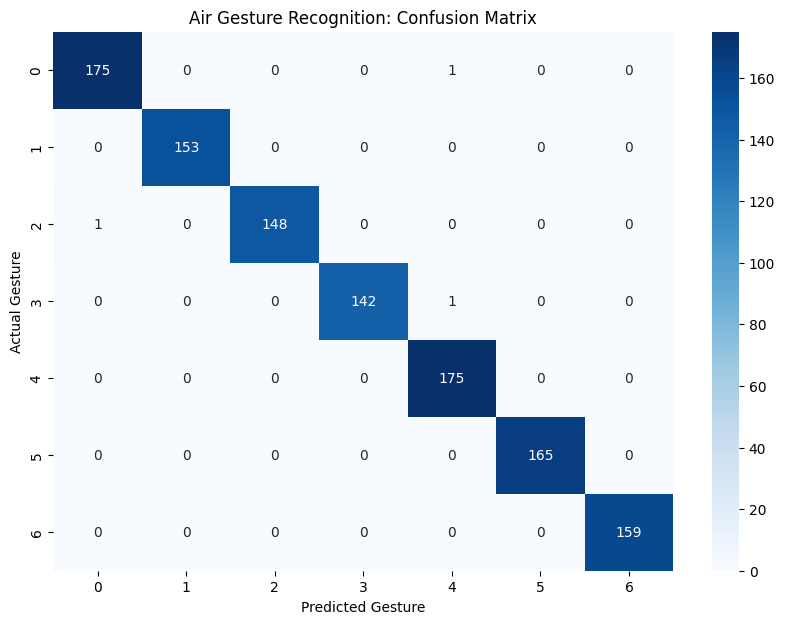

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Air Gesture Recognition: Confusion Matrix')
plt.xlabel('Predicted Gesture')
plt.ylabel('Actual Gesture')
plt.show()

### **Bagging**

In [7]:
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier

# Base model (SVM)
svm = SVC(kernel='rbf', probability=True)

# Bagging with SVM
bagging_svm = BaggingClassifier(
    estimator=svm,
    n_estimators=10,
    max_samples=0.8,
    bootstrap=True,
    random_state=42
)

In [8]:
bagging_svm.fit(X_train, y_train)

BaggingClassifier(estimator=SVC(probability=True), max_samples=0.8,
                  random_state=42)

In [9]:
y_pred = bagging_svm.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))

y_train_pred = bagging_svm.predict(X_train)
y_test_pred = bagging_svm.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9973214285714286
Train Accuracy: 0.996875
Test Accuracy: 0.9973214285714286

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      0.99       176
           1       1.00      1.00      1.00       153
           2       0.99      1.00      1.00       149
           3       0.99      1.00      1.00       143
           4       0.99      1.00      1.00       175
           5       1.00      0.99      1.00       165
           6       1.00      1.00      1.00       159

    accuracy                           1.00      1120
   macro avg       1.00      1.00      1.00      1120
weighted avg       1.00      1.00      1.00      1120



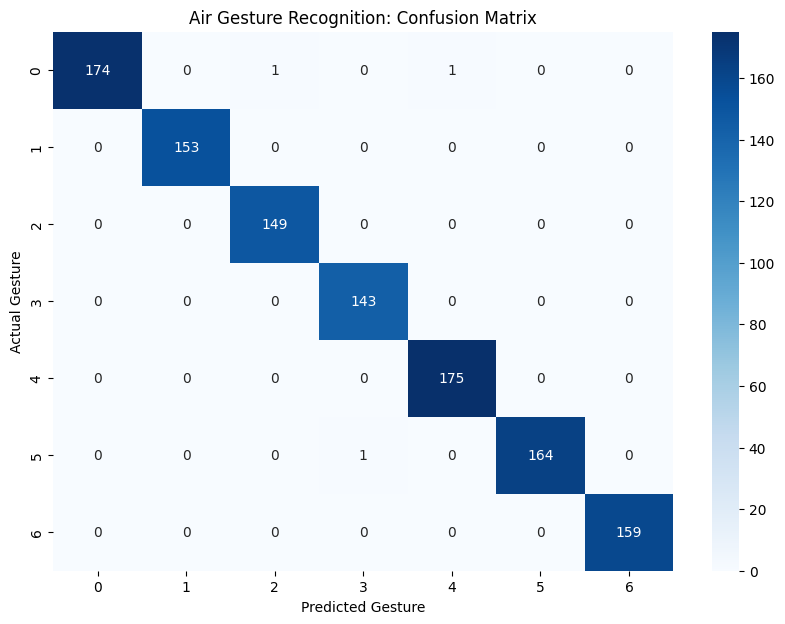

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Air Gesture Recognition: Confusion Matrix')
plt.xlabel('Predicted Gesture')
plt.ylabel('Actual Gesture')
plt.show()

### **Boosting**

In [6]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.svm import SVC

# Base model (SVM must support sample weights)
svm = SVC(kernel='linear', probability=True)

# Boosting model
boost_model = AdaBoostClassifier(
    estimator=svm,
    n_estimators=10,
    learning_rate=1.0,
    random_state=42
)


In [7]:
boost_model.fit(X_train, y_train)

c:\OneDrive\Desktop\PRJ_303\magic_pen\.venv\lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


AdaBoostClassifier(estimator=SVC(kernel='linear', probability=True),
                   n_estimators=10, random_state=42)

In [9]:
y_pred = boost_model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))

y_train_pred = boost_model.predict(X_train)
y_test_pred = boost_model.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9455357142857143
Train Accuracy: 0.9533482142857143
Test Accuracy: 0.9455357142857143

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.71      0.82       176
           1       1.00      1.00      1.00       153
           2       0.74      0.98      0.84       149
           3       1.00      0.96      0.98       143
           4       0.99      1.00      0.99       175
           5       0.97      0.99      0.98       165
           6       1.00      1.00      1.00       159

    accuracy                           0.95      1120
   macro avg       0.95      0.95      0.95      1120
weighted avg       0.96      0.95      0.95      1120



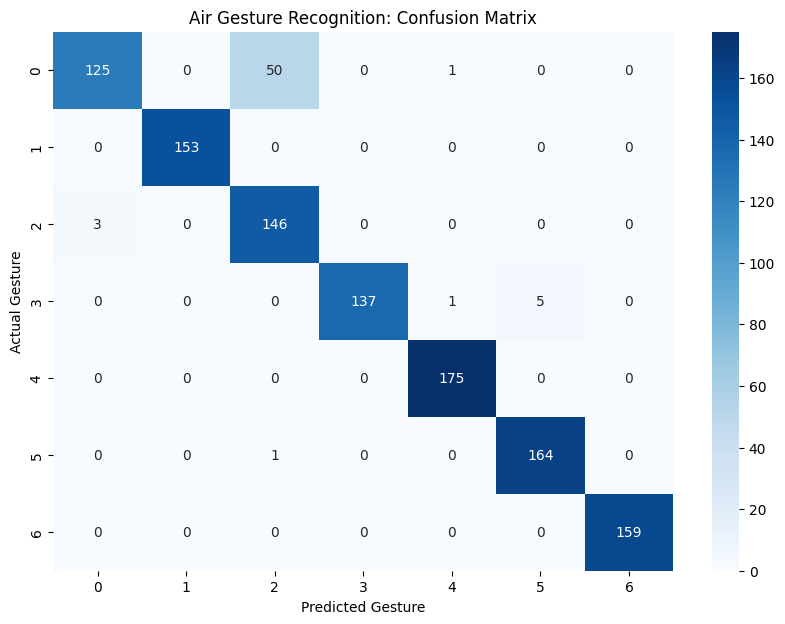

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Air Gesture Recognition: Confusion Matrix')
plt.xlabel('Predicted Gesture')
plt.ylabel('Actual Gesture')
plt.show()

### **Stacking**

In [6]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier

# Base models (4 models)
estimators = [
    ('svm', SVC(probability=True)),
    ('dt', DecisionTreeClassifier(max_depth=3)),
    ('knn', KNeighborsClassifier(n_neighbors=5)),
    ('lr', LogisticRegression(max_iter=1000))
]

In [7]:
# Meta-model (final model)
meta_model = LogisticRegression()

# Stacking model
stack_model = StackingClassifier(
    estimators=estimators,
    final_estimator=meta_model,
    cv=5
)

In [8]:
stack_model.fit(X_train, y_train)

StackingClassifier(cv=5,
                   estimators=[('svm', SVC(probability=True)),
                               ('dt', DecisionTreeClassifier(max_depth=3)),
                               ('knn', KNeighborsClassifier()),
                               ('lr', LogisticRegression(max_iter=1000))],
                   final_estimator=LogisticRegression())

In [9]:
y_pred = stack_model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))

y_train_pred = stack_model.predict(X_train)
y_test_pred = stack_model.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9982142857142857
Train Accuracy: 0.9991071428571429
Test Accuracy: 0.9982142857142857

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      0.99       176
           1       1.00      1.00      1.00       153
           2       0.99      1.00      1.00       149
           3       1.00      1.00      1.00       143
           4       0.99      1.00      1.00       175
           5       1.00      1.00      1.00       165
           6       1.00      1.00      1.00       159

    accuracy                           1.00      1120
   macro avg       1.00      1.00      1.00      1120
weighted avg       1.00      1.00      1.00      1120



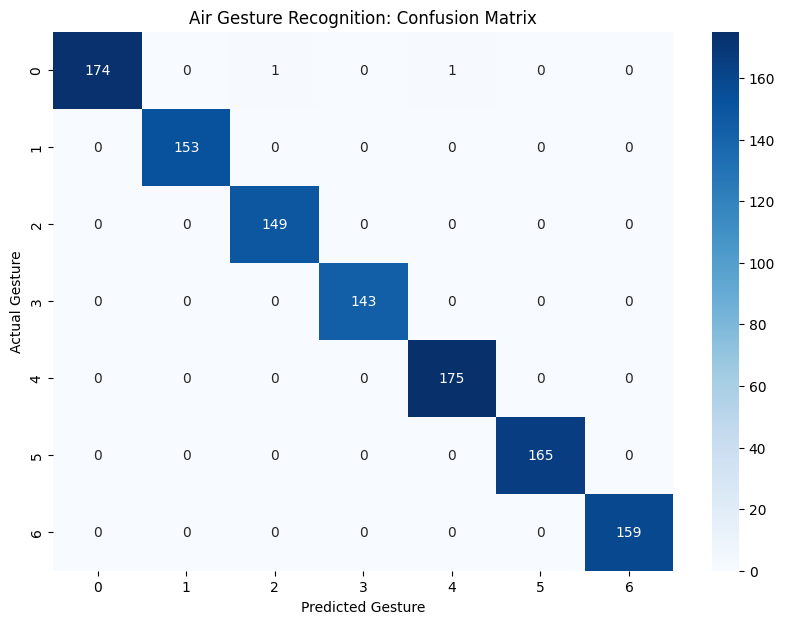

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Air Gesture Recognition: Confusion Matrix')
plt.xlabel('Predicted Gesture')
plt.ylabel('Actual Gesture')
plt.show()